# 👑 Topic 2: Multi-Agent Supervisor Pattern with RAG
### Centralized Multi-Agent Orchestration via `langgraph-supervisor`

---

## 📌 Architectural Overview
The **Agent Supervisor Pattern** introduces a central manager node that coordinates specialized worker agents. Instead of workers passing messages directly to one another (which can lead to chaotic circular conversations), the **Supervisor Agent** controls all communication flow, task delegation, and synthesis.

### Key Characteristics:
- **Centralized Routing:** The supervisor inspects incoming requests, breaks them down into sub-tasks, and delegates to the appropriate domain expert.
- **Strict Role Separation:** Worker agents are domain specialists:
  1. **🔍 Research Agent:** Equipped with RAG Vector Retrieval (`InternalResearchNotes`) and live web search (`TavilySearch`). Focuses purely on factual discovery.
  2. **🧮 Math Agent:** Equipped with deterministic calculator tools (`add`, `multiply`, `divide`). Handles analytical math calculations.
- **Handoff Back Mechanism:** Workers execute their tools, summarize findings, and return control back to the supervisor via `add_handoff_back_messages=True`.
- **Final Synthesis:** Once all sub-tasks are complete, the supervisor synthesizes a cohesive, unified response for the user.

---

### 🎨 Architecture Diagram
![Multi-Agent Supervisor Architecture](images/multi_agent_supervisor_architecture.png)


### 1. Environment & API Keys Setup
Loads API keys from the root `.env` file, suppresses OpenMP duplicate library warnings on Windows, and prevents HuggingFace hub network checks.

In [ ]:
import os
import sys

# Suppress OpenMP runtime conflicts on Windows
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
# Use cached HuggingFace models offline without network stalls
os.environ["HF_HUB_OFFLINE"] = "1"

from dotenv import load_dotenv, find_dotenv

# Load keys from workspace root .env
load_dotenv(find_dotenv(usecwd=True))
sys.path.append(os.path.abspath(".."))

print("🔑 Environment Configuration:")
print("- TAVILY_API_KEY:", "✅ Configured" if os.getenv("TAVILY_API_KEY") else "❌ Missing")
print("- GROQ_API_KEY:  ", "✅ Configured" if os.getenv("GROQ_API_KEY") else "❌ Missing")
print("- OPENAI_API_KEY:", "✅ Configured" if os.getenv("OPENAI_API_KEY") else "❌ Missing")

### 2. Centralized LLM Initialization
Initializes the chat model using `llm_config.get_llm()` for high-throughput reasoning and function calling.

In [ ]:
from llm_config import get_llm

llm = get_llm(temperature=0.1)
test_res = llm.invoke("Hello! Give a 1-sentence description of the agent supervisor pattern.")
print("🤖 LLM Response:", test_res.content.strip())

### 3. Specialized Tools Setup
We equip our specialists with domain-focused tools:
- **Research Tools:** FAISS vector store over `data/research_notes.txt` + `TavilySearch`
- **Math Tools:** Deterministic arithmetic functions (`add`, `multiply`, `divide`)

In [ ]:
from pydantic import BaseModel, Field
from langchain_core.tools import StructuredTool
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_tavily import TavilySearch

class RetrieverQueryInput(BaseModel):
    query: str = Field(description="Search query to retrieve empirical research notes and experimental data")

def make_retriever_tool_from_text(file_path: str, name: str, desc: str):
    possible_paths = [
        file_path,
        os.path.join("..", file_path),
        os.path.join("..", "data", os.path.basename(file_path)),
        os.path.join("data", os.path.basename(file_path)),
        os.path.join("..", "data", "research_notes.txt"),
        os.path.join("data", "research_notes.txt"),
    ]
    resolved_path = next((p for p in possible_paths if os.path.exists(p)), os.path.join("..", "data", "research_notes.txt"))
    print(f"📁 Loading Knowledge Base from: {resolved_path}")
    
    docs = TextLoader(resolved_path, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    emb = HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        model_kwargs={"local_files_only": True}
    )
    vs = FAISS.from_documents(chunks, emb)
    retriever = vs.as_retriever(search_kwargs={"k": 2})

    def tool_func(query: str) -> str:
        print(f"📚 [Retriever Tool] Query: '{query}'")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results[:2])

    return StructuredTool.from_function(
        func=tool_func,
        name=name,
        description=desc,
        args_schema=RetrieverQueryInput
    )

# RAG Knowledge Retriever
internal_tool_1 = make_retriever_tool_from_text(
    "research_notes.txt",
    "InternalResearchNotes",
    "Search internal research notes for experimental results, model evaluations, accuracy metrics, and benchmark data."
)

# Live Web Search
web_search = TavilySearch(max_results=3)

# Deterministic Math Tools
def add(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b

def multiply(a: float, b: float) -> float:
    """Multiply two numbers."""
    return a * b

def divide(a: float, b: float) -> float:
    """Divide two numbers."""
    return a / b

print("✅ Research and Math tools initialized successfully.")

### 4. Specialist Worker Agents
We instantiate two ReAct worker agents using `create_react_agent`.
Crucially, each worker is given prompt instructions:
1. Focus strictly on its assigned domain (no cross-domain attempts).
2. Report results directly back to the supervisor when done without extra conversational filler.


In [ ]:
from langgraph.prebuilt import create_react_agent

# 1. Research Specialist Agent
research_agent = create_react_agent(
    model=llm,
    tools=[web_search, internal_tool_1],
    prompt=(
        "You are a research agent.\n\n"
        "INSTRUCTIONS:\n"
        "- Assist ONLY with research-related tasks, DO NOT do any math\n"
        "- Use the tools (InternalResearchNotes, TavilySearch) to retrieve facts\n"
        "- After you are done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your work, do NOT include ANY other text."
    ),
    name="research_agent"
)

# 2. Math Specialist Agent
math_agent = create_react_agent(
    model=llm,
    tools=[add, multiply, divide],
    prompt=(
        "You are a math agent.\n\n"
        "INSTRUCTIONS:\n"
        "- Assist ONLY with math-related tasks\n"
        "- Use your arithmetic tools (add, multiply, divide) to calculate deterministic answers\n"
        "- After you are done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your calculation, do NOT include ANY other text."
    ),
    name="math_agent"
)

print("✅ Specialist worker agents created:")
print("- research_agent with tools:", [t.name for t in [web_search, internal_tool_1]])
print("- math_agent with tools: ['add', 'multiply', 'divide']")

### 5. Supervisor Agent Creation
We assemble the centralized supervisor using `langgraph_supervisor.create_supervisor`:
- **`model`:** Central orchestrator LLM.
- **`agents`:** The registered list of specialist workers `[research_agent, math_agent]`.
- **`prompt`:** Directs the supervisor to route tasks to one worker at a time and synthesize findings.
- **`add_handoff_back_messages=True`:** Ensures handoff transitions are recorded in the conversation trace.
- **`output_mode="full_history"`:** Keeps the full context of intermediate worker actions.


In [ ]:
from langgraph_supervisor import create_supervisor

supervisor = create_supervisor(
    model=llm,
    agents=[research_agent, math_agent],
    prompt=(
        "You are a supervisor managing two agents:\n"
        "- a research agent: Assign research and document retrieval tasks to this agent\n"
        "- a math agent: Assign math and arithmetic calculation tasks to this agent\n"
        "Assign work to one agent at a time, do not call agents in parallel.\n"
        "Do not do any work yourself. Once all sub-tasks are answered, synthesize the final answer."
    ),
    add_handoff_back_messages=True,
    output_mode="full_history"
).compile()

print("✅ Supervisor compiled successfully!")

### 6. Visualizing the Supervisor Execution Graph
Renders the compiled hub-and-spoke graph showing handoffs to `research_agent` and `math_agent`.

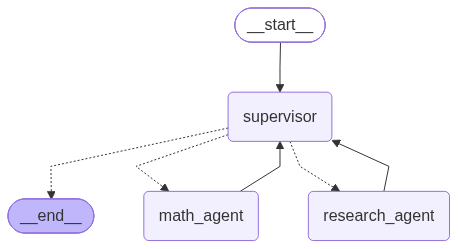

In [ ]:
from IPython.display import Image, display

try:
    graph_png = supervisor.get_graph().draw_mermaid_png()
    display(Image(graph_png))
    with open("images/multi_agent_supervisor_graph.png", "wb") as f:
        f.write(graph_png)
    print("📊 Graph image saved to images/multi_agent_supervisor_graph.png")
except Exception as e:
    print(f"Mermaid render note: {e}")
    try:
        print(supervisor.get_graph().draw_ascii())
    except Exception:
        pass

### 7. End-to-End Multi-Domain Execution
We give the supervisor a complex multi-domain query requiring both empirical research retrieval and arithmetic calculation:
> *"List all the transformer variants evaluated in our internal notes, identify which one had the highest accuracy on TinyImageNet, and then calculate (15 * 4) + 20."*


In [ ]:
query = (
    "List all the transformer variants evaluated in our internal notes, "
    "identify which one had the highest accuracy on TinyImageNet, "
    "and then calculate (15 * 4) + 20."
)
print(f"🚀 Invoking Supervisor with Query:\n'{query}'\n" + "="*70)

response = supervisor.invoke({
    "messages": [{"role": "user", "content": query}]
})

print(f"\n🎯 Execution completed! Total messages in history: {len(response['messages'])}\n")
print("="*70 + "\n🏁 FINAL SUPERVISOR SYNTHESIS:\n" + "="*70)
print(response["messages"][-1].content)

### 8. Message Trajectory & Handoff Trace
Traces every step of the orchestration:
1. User prompt
2. Supervisor delegates to `research_agent`
3. `research_agent` executes RAG tool and transfers back
4. Supervisor delegates calculation to `math_agent`
5. `math_agent` executes math tool and transfers back
6. Supervisor produces final consolidated answer


In [ ]:
print("📜 Supervisor Orchestration Trajectory:")
for i, msg in enumerate(response["messages"]):
    name = getattr(msg, "name", None) or getattr(msg, "role", None) or msg.type
    content = str(msg.content)[:140].replace("\n", " ")
    print(f"[{i:02d}] {name.upper():<20} : {content}...")

### 9. Architectural Summary & Comparison

| Aspect | Peer-to-Peer Network (Topic 1) | Centralized Supervisor (Topic 2) |
| :--- | :--- | :--- |
| **Topology** | Mesh / Ring (Any-to-Any) | Hub-and-Spoke (Star) |
| **Control Point** | Distributed among individual agents | Single central supervisor |
| **Scalability** | Best for 2-3 agents | Scales comfortably to 5-8 agents |
| **Governance** | Difficult to monitor and enforce guardrails | Strict audit trail and deterministic handoffs |
| **Fault Tolerance** | If one agent loops, the entire ring stalls | Supervisor can intercept errors and re-route |
| **When to Use** | Brainstorming, drafting & editing, paired peer workflows | Multi-domain tasks (RAG + Math + Code + Database) |
